# 03 · Behavioural clustering (K-Means)

**Question:** without pre-set rules, what natural customer groups exist?

### What v1 got wrong
1. `k = 4` was hard-coded, with a code comment asking "how was k decided?". There was no evidence for it.
2. The names were typed by hand and didn't match the clusters. The cluster with **2-day recency and £784k average revenue** was called "Dormant / At Risk".
3. Two notebooks used **different** name maps for the same clusters.
4. MinMax scaling on raw revenue let the two huge accounts dominate.

In [1]:
import sys
from pathlib import Path

# make the src/ package importable from notebooks/ (no hard-coded C:\ paths)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1 else f"{v:,.2f}")

from autosales.data import load_raw, build_order_lines, build_order_summary, build_customer_features
from autosales import kpis, segmentation, clustering, modelling, plots
%matplotlib inline

In [2]:
lines = build_order_lines(load_raw())
orders = build_order_summary(lines)
cust = segmentation.add_rfm(build_customer_features(lines, orders))
cust[["frequency", "monetary", "recency_days"]].describe().T

,count,mean,std,min,25%,50%,75%,max
frequency,89.00,3.35,2.97,1.00,2.00,3.00,3.00,26.00
monetary,89.00,"109,665.41","111,837.42","9,129.35","70,488.44","87,489.23","120,562.74","912,294.11"
recency_days,89.00,180.61,128.89,1.00,76.00,185.00,231.00,496.00


## 1. Features
Revenue and order counts are heavily right-skewed (two accounts hold 16% of revenue), so we use **log** frequency and **log** revenue, then standardise. Product breadth is left out because it's mostly a by-product of order count.

In [3]:
X = clustering.feature_matrix(cust)
X[:3].round(2)

array([[ 0.13,  0.  ,  0.96],
       [-0.9 ,  0.  , -0.39],
       [ 0.67, -0.85,  0.1 ]])

## 2. Choosing k with evidence
The **silhouette score** measures how well each customer sits in its own cluster compared with the nearest other one (closer to 1 is better).

In [4]:
clustered, profile, selection = clustering.fit_clusters(cust)
selection

,k,silhouette,inertia,chosen
0,2,0.3891,167.20,False
1,3,0.4400,99.03,False
2,4,0.4498,77.18,True
3,5,0.3728,58.22,False
4,6,0.3887,44.72,False
5,7,0.4170,34.77,False
6,8,0.4091,30.65,False


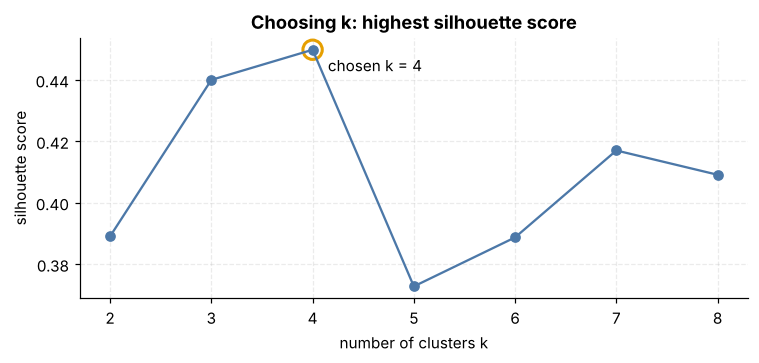

In [5]:
_ = plots.k_selection(selection)

k = 4 has the highest silhouette (0.45, just ahead of k = 3 at 0.44), so v1's choice of four happened to be reasonable. Now it's backed by evidence.

## 3. Labels generated from each cluster's own profile
A cluster is called *High / Mid / Low-value* by comparing its median revenue with the overall median (> 1.5× or < 0.75×), and *Active / Cooling / Lapsed* by its median recency (≤ 90 / ≤ 270 / > 270 days). The names can't drift away from the data.

In [6]:
profile

,cluster,customers,recency_days,frequency,monetary,avg_order_value,total_revenue,label,revenue_share
0,0,54,116.50,3.00,"104,466.17","30,365.15","5,973,853.61",Mid-value · Cooling,0.6121
1,1,28,274.00,2.00,"72,747.32","36,321.66","2,092,842.33",Mid-value · Lapsed,0.2144
2,3,2,2.00,21.50,"783,576.08","36,804.65","1,567,152.17",High-value · Active,0.1606
3,2,5,181.00,3.00,"26,479.26","8,360.02","126,373.60",Low-value · Cooling,0.0129


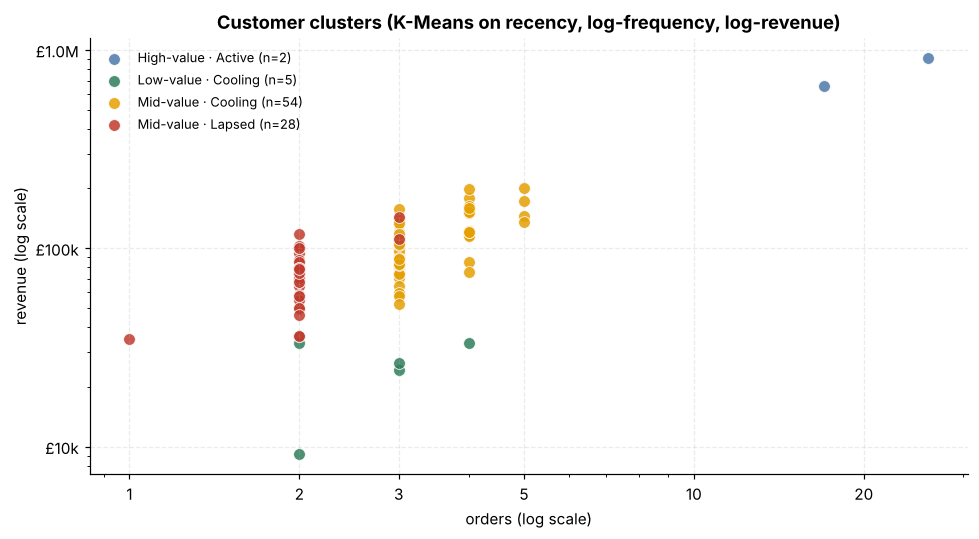

In [7]:
_ = plots.clusters(clustered)

## 4. How the clusters relate to RFM segments

In [8]:
pd.crosstab(clustered.cluster_label, clustered.rfm_segment, margins=True)

rfm_segment,At Risk – High Value,Champions,Hibernating,Potential Loyalists,All
cluster_label,,,,,
High-value · Active,0,2,0,0,2
Low-value · Cooling,0,0,2,3,5
Mid-value · Cooling,11,26,3,14,54
Mid-value · Lapsed,2,0,26,0,28
All,13,28,31,17,89


**Takeaways**
- **High-value · Active (2 customers)**: Euro Shopping Channel and Mini Gifts Distributors, 16% of revenue between them. That's real concentration risk.
- **Mid-value · Cooling (54)**: the core of the business, 61% of revenue.
- **Mid-value · Lapsed (28)**: no order in about 9 months, 21% of historic revenue. This group overlaps heavily with RFM "Hibernating" and "At Risk".
- **Low-value · Cooling (5)**: small average orders (~£8k against ~£30k typical).

The clustering confirms the RFM picture independently, which is a useful robustness check.